# Chemistry Grapn Neural Network (GNN) Example
We will apply a GCN and a edge-conditioned MPNN to the delaney dataset

# Install Packages
Only run if you do not have packages installed

In [ ]:
%pip install rdkit
%pip install pandas
%pip install scikit-learn
%pip install matplotlib
%pip install torch torchvision torchaudio torch-geometric

# Load data and set seed

In [1]:
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn

from rdkit import Chem

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, NNConv, MessagePassing, global_mean_pool
from torch_geometric.utils import softmax, to_dense_batch


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

df = pd.read_csv("delaney.csv")



C:\Users\allis\anaconda3\envs\AI_class\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


# Methods for getting atom and bond features

In [2]:
#get a one hot encoding of the value, with the final category representing other
def one_hot_with_other(value, choices):
    result = [0.0] * (len(choices) + 1)

    if value in choices:
        result[choices.index(value)] = 1.0
    else:
        result[-1] = 1.0

    return result

# here is alist of all values that will be accepted for different atom properties
ATOM_TYPES = ["C", "N", "O", "S", "F", "Cl", "Br", "I", "P"]

DEGREES = [0, 1, 2, 3, 4, 5]

FORMAL_CHARGES = [-2, -1, 0, 1, 2]

HYBRIDIZATIONS = [
    Chem.rdchem.HybridizationType.SP,
    Chem.rdchem.HybridizationType.SP2,
    Chem.rdchem.HybridizationType.SP3,
    Chem.rdchem.HybridizationType.SP3D,
    Chem.rdchem.HybridizationType.SP3D2,
]

NUM_HYDROGENS = [0, 1, 2, 3, 4]

#get the one hot tom features
def atom_features(atom):
    features = []

    features += one_hot_with_other(
        atom.GetSymbol(), ATOM_TYPES
    )

    features += one_hot_with_other(
        atom.GetDegree(), DEGREES
    )

    features += one_hot_with_other(
        atom.GetFormalCharge(), FORMAL_CHARGES
    )

    features += one_hot_with_other(
        atom.GetHybridization(), HYBRIDIZATIONS
    )

    features.append(float(atom.GetIsAromatic()))
    features.append(float(atom.IsInRing()))

    features += one_hot_with_other(
        atom.GetTotalNumHs(), NUM_HYDROGENS
    )

    return features

#do the same thing for bond features
BOND_TYPES = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.TRIPLE,
    Chem.rdchem.BondType.AROMATIC,
]

BOND_STEREO = [
    Chem.rdchem.BondStereo.STEREONONE,
    Chem.rdchem.BondStereo.STEREOANY,
    Chem.rdchem.BondStereo.STEREOZ,
    Chem.rdchem.BondStereo.STEREOE,
    Chem.rdchem.BondStereo.STEREOCIS,
    Chem.rdchem.BondStereo.STEREOTRANS,
]

#method gets one hot encoding for categorical features and binary value for binary features
def bond_features(bond):
    features = []

    features += one_hot_with_other(
        bond.GetBondType(), BOND_TYPES
    )

    features.append(float(bond.GetIsConjugated()))
    features.append(float(bond.IsInRing()))

    features += one_hot_with_other(
        bond.GetStereo(), BOND_STEREO
    )

    return features

#calculate sizes for node and edge features with an example molecule
NODE_DIM = len(
    atom_features(Chem.MolFromSmiles("C").GetAtomWithIdx(0))
)

EDGE_DIM = len(
    bond_features(Chem.MolFromSmiles("CC").GetBondWithIdx(0))
)

# Create graphs for pytorch

In [3]:
#converta smiles string to a graphy
def smiles_to_graph(smiles, target):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # Atom features to pytorch tensor
    x = torch.tensor(
        [atom_features(atom) for atom in mol.GetAtoms()],
        dtype=torch.float32
    )

    edge_indices = []
    edge_attributes = []

    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        features = bond_features(bond)

        # Both directions for each undirected chemical bond
        edge_indices.extend([[i, j], [j, i]])
        edge_attributes.extend([features, features])

    if edge_indices:
        edge_index = torch.tensor(
            edge_indices, dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_attributes, dtype=torch.float32
        )
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, EDGE_DIM), dtype=torch.float32)
    
    #make pytorch tensor for target property
    y = torch.tensor([target], dtype=torch.float32)

    return Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr,
        y=y
    )


graphs = []

#make graphs with smiles and prediction target column
for smiles, target in zip(df["SMILES"], df["measured log(solubility:mol/L)"]):
    graph = smiles_to_graph(smiles, target)

    if graph is not None:
        graphs.append(graph)

print("Graphs created:", len(graphs))
print("First graph:", graphs[0])


Graphs created: 1144
First graph: Data(x=[6, 37], edge_index=[2, 10], edge_attr=[10, 14], y=[1])


# Split data to training and validation

In [4]:
indices = np.arange(len(graphs))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED
)

train_graphs = [graphs[i] for i in train_idx]
val_graphs = [graphs[i] for i in val_idx]


train_loader = DataLoader(
    train_graphs, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_graphs, batch_size=32, shuffle=False
)


print("Training:", len(train_graphs))
print("Validation:", len(val_graphs))


Training: 915
Validation: 229


# Edge-conditioned MPNN with attention over neighboring atoms
Each bond generates an edge-specific transformation of the source atom features. An attention score is then learned for each directed bond and normalized with a softmax over incoming neighbors of the destination atom. This replaces the equal-weight sum in NNConv. Both the message and the attention score use bond features.

In [5]:
#we need a new class to incorporate attention into the message passing
class EdgeAttentionConv(MessagePassing):
    """Bond-conditioned messages with softmax attention across incoming edges."""
    def __init__(self, in_channels, out_channels, edge_dim, hidden_dim=32):
        super().__init__(aggr="add", node_dim=0) #will sum messages
        self.in_channels = in_channels
        self.out_channels = out_channels

        # Each bond produces a matrix that transforms the source atom embedding.
        self.edge_network = nn.Sequential(
            nn.Linear(edge_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, in_channels * out_channels)
        )

        # Attention score depends on source, destination, AND bond features.
        self.attention_network = nn.Sequential(
            nn.Linear(2 * in_channels + edge_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
        #root network performs the update on the atom receiving messages
        #this will be added to the message
        self.root = nn.Linear(in_channels, out_channels)

    def forward(self, x, edge_index, edge_attr):
        # propagate() collects messages from source nodes and aggregates at targets
        neighbor_messages = self.propagate(
            edge_index, x=x, edge_attr=edge_attr, size=(x.size(0), x.size(0))
        )
        return neighbor_messages + self.root(x)

    def message(self, x_i, x_j, edge_attr, index, ptr, size_i):
        # x_j: source node, x_i: destination node, one row per directed bond
        weights = self.edge_network(edge_attr).view(
            -1, self.in_channels, self.out_channels
        )
        messages = torch.bmm(x_j.unsqueeze(1), weights).squeeze(1)

        logits = self.attention_network(
            torch.cat([x_i, x_j, edge_attr], dim=-1)
        ).squeeze(-1)
        # normalize over the *incoming edges of each destination node*
        alpha = softmax(logits, index, ptr=ptr, num_nodes=size_i)
        return messages * alpha.unsqueeze(-1)
    
class EdgeMPNNModel(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden_dim=32):
        super().__init__()
        
        #use our custom EdgeAttentionConv as the layers in the GNN
        self.conv1 = EdgeAttentionConv(node_dim, hidden_dim, edge_dim, hidden_dim)
        self.conv2 = EdgeAttentionConv(hidden_dim, hidden_dim, edge_dim, hidden_dim)

        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr

        x = torch.relu(
            self.conv1(x, edge_index, edge_attr)
        )

        x = torch.relu(
            self.conv2(x, edge_index, edge_attr)
        )

        x = global_mean_pool(x, data.batch)

        return self.regressor(x).view(-1)


# Global graph Transformer (hybrid local-message passing/global transformer)
Unlike the preceding MPNN, whose attention is restricted to bonded neighbors, this model uses global multi-head self-attention across every atom in each molecule. A bond-aware NNConv first provides local structural information; then a standard Transformer encoder lets distant atoms interact directly. Padding masks ensure atoms in different molecules or padding positions cannot attend to one another. 

In [14]:
class GlobalGraphTransformerModel(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden_dim=32, num_heads=4,
                 num_transformer_layers=2, dropout=0.1):
        super().__init__()
        if hidden_dim % num_heads != 0:
            raise ValueError("hidden_dim must be divisible by num_heads")
        #local message passing part
        # Local bond-conditioned aggregation encodes the molecular connectivity.
        edge_nn = nn.Sequential(
            nn.Linear(edge_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, node_dim * hidden_dim)
        )
        self.local_conv = NNConv(node_dim, hidden_dim, nn=edge_nn, aggr="add")
        
        #transformer part
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim * 4,
            dropout=dropout,
            batch_first=True,
            activation="relu"
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=num_transformer_layers,
            enable_nested_tensor=False
        )
        
        #regression head
        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, data):
        x = torch.relu(self.local_conv(data.x, data.edge_index, data.edge_attr))

        # [total_atoms, hidden_dim] -> [batch, max_atoms, hidden_dim]
        dense_x, mask = to_dense_batch(x, data.batch)

        # Every real atom attends to all real atoms in its own molecule.
        # The padding mask is True for positions that should be ignored.
        dense_x = self.transformer(
            dense_x, src_key_padding_mask=~mask
        )

        # Masked mean pool gives one vector per molecule.
        dense_x = dense_x.masked_fill(~mask.unsqueeze(-1), 0.0)
        graph_embeddings = dense_x.sum(dim=1) / mask.sum(
            dim=1, keepdim=True
        ).clamp(min=1)
        return self.regressor(graph_embeddings).view(-1)


# Train models

In [15]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    n_samples = 0

    for batch in loader:
        batch = batch.to(device)

        optimizer.zero_grad()

        predictions = model(batch)
        targets = batch.y.view(-1)

        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        n_samples += batch_size

    return total_loss / n_samples


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()

    predictions = []
    targets = []

    for batch in loader:
        batch = batch.to(device)

        pred = model(batch)
        target = batch.y.view(-1)

        predictions.append(pred.cpu().numpy())
        targets.append(target.cpu().numpy())

    predictions = np.concatenate(predictions)
    targets = np.concatenate(targets)

    rmse = np.sqrt(mean_squared_error(targets, predictions))
    mae = mean_absolute_error(targets, predictions)
    r2 = r2_score(targets, predictions)

    return {
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
        "predictions": predictions,
        "targets": targets
    }


def train_model(
    model,
    train_loader,
    val_loader,
    max_epochs=300,
    learning_rate=0.001
):
    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    criterion = nn.MSELoss()

    history = {"train_loss": [], "val_rmse": []}

    for epoch in range(max_epochs):
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion
        )

        val_results = evaluate(model, val_loader)
        val_rmse = val_results["rmse"]

        history["train_loss"].append(train_loss)
        history["val_rmse"].append(val_rmse)


    return model, history


#create and train models
HIDDEN_DIM = 32

mpnn_model = EdgeMPNNModel(
    node_dim=NODE_DIM,
    edge_dim=EDGE_DIM,
    hidden_dim=HIDDEN_DIM
)

transformer_model = GlobalGraphTransformerModel(
    node_dim=NODE_DIM,
    edge_dim=EDGE_DIM,
    hidden_dim=HIDDEN_DIM,
    num_heads=4,
    num_transformer_layers=2
)

#compare number of parameters, transformer has fewer because attention is only being applied in one of the two layers
print("MPNN parameters:", sum(
    p.numel() for p in mpnn_model.parameters()
))

print("Graph Transformer parameters:", sum(
    p.numel() for p in transformer_model.parameters()
))


print("\nTraining attention-based edge-conditioned MPNN:")
mpnn_model, mpnn_history = train_model(
    mpnn_model, train_loader, val_loader
)

print("\nTraining global graph Transformer:")
transformer_model, transformer_history = train_model(
    transformer_model, train_loader, val_loader
)




MPNN parameters: 82627
Graph Transformer parameters: 67265

Training attention-based edge-conditioned MPNN:

Training global graph Transformer:


# Plot training progress

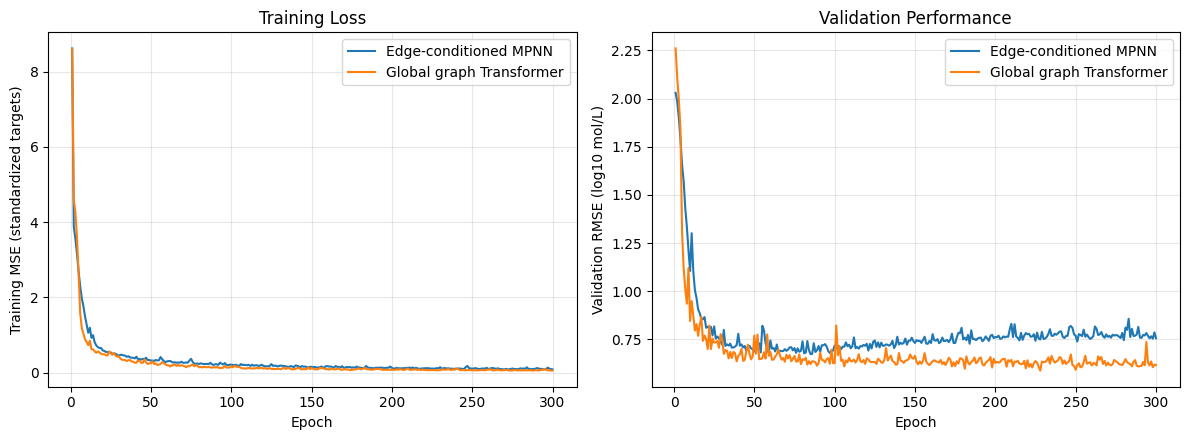

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

histories = {
    "Edge-conditioned MPNN": mpnn_history,
    "Global graph Transformer": transformer_history
}

# Training MSE loss
for name, history in histories.items():
    axes[0].plot(
        range(1, len(history["train_loss"]) + 1),
        history["train_loss"],
        label=name
    )

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training MSE (standardized targets)")
axes[0].set_title("Training Loss")
axes[0].legend()

# Validation RMSE
for name, history in histories.items():
    axes[1].plot(
        range(1, len(history["val_rmse"]) + 1),
        history["val_rmse"],
        label=name
    )

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation RMSE (log10 mol/L)")
axes[1].set_title("Validation Performance")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Plot true vs predicted for validation set

                      Model   RMSE    MAE     R2
0     Edge-conditioned MPNN  0.756  0.535  0.869
1  Global graph Transformer  0.616  0.434  0.913


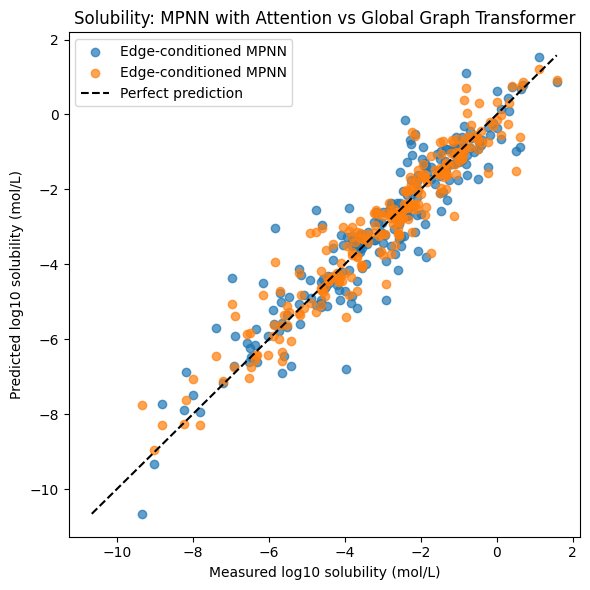

In [17]:
mpnn_results = evaluate(mpnn_model, val_loader)
global_graph_transformer_results  = evaluate(transformer_model, val_loader)

results_df = pd.DataFrame({
    "Model": ["Edge-conditioned MPNN","Global graph Transformer"],
    "RMSE": [
        mpnn_results["rmse"],
        global_graph_transformer_results["rmse"]
        
    ],
    "MAE": [
        mpnn_results["mae"],
        global_graph_transformer_results["mae"]
    ],
    "R2": [
        mpnn_results["r2"],
        global_graph_transformer_results["r2"]
    ]
})

print(results_df.round(3))


plt.figure(figsize=(6, 6))

plt.scatter(
    mpnn_results["targets"],
    mpnn_results["predictions"],
    alpha=0.7,
    label="Edge-conditioned MPNN"
)

plt.scatter(
    global_graph_transformer_results["targets"],
    global_graph_transformer_results["predictions"],
    alpha=0.7,
    label="Edge-conditioned MPNN"
)


all_targets = mpnn_results["targets"]

lower = min(
    all_targets.min(),
    mpnn_results["predictions"].min(),
    global_graph_transformer_results["predictions"].min()
)

upper = max(
    all_targets.max(),
    mpnn_results["predictions"].max(),
    global_graph_transformer_results["predictions"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Measured log10 solubility (mol/L)")
plt.ylabel("Predicted log10 solubility (mol/L)")
plt.title("Solubility: MPNN with Attention vs Global Graph Transformer")
plt.legend()
plt.tight_layout()
plt.show()
